# Hotel Booking Cancellation Prediction System

In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

In [6]:
#Loading Dataset
df = pd.read_csv(r"C:\Users\Sreeram\Downloads\hotel_bookings.csv")

In [7]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [8]:
df.shape

(119390, 32)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [10]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [13]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='object')

In [14]:
df.dtypes

hotel                              object
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                 object
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                               object
country                            object
market_segment                     object
distribution_channel               object
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                 object
assigned_room_type                 object
booking_changes                     int64
deposit_type                       object
agent                             

In [18]:
#Checking Missing Values
df.isnull().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [19]:
df.isnull().sum()[df.isnull().sum()>0]

children         4
country        488
agent        16340
company     112593
dtype: int64

In [20]:
#Checking Duplicate Rows
df.duplicated().sum()

np.int64(31994)

In [21]:
df[df.duplicated()].head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
22,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,No Deposit,250.0,NaN,0,Transient,84.67,0,1,Check-Out,2015-07-07
43,Resort Hotel,0,70,2015,July,27,2,2,3,2,...,No Deposit,250.0,NaN,0,Transient,137.00,0,1,Check-Out,2015-07-07
138,Resort Hotel,1,5,2015,July,28,5,1,0,2,...,No Deposit,240.0,NaN,0,Transient,97.00,0,0,Canceled,2015-07-01
200,Resort Hotel,0,0,2015,July,28,7,0,1,1,...,No Deposit,240.0,NaN,0,Transient,109.80,0,3,Check-Out,2015-07-08


In [22]:
#Understand Our Target
df["is_canceled"].value_counts()

is_canceled
0    75166
1    44224
Name: count, dtype: int64

In [23]:
df["is_canceled"].value_counts(normalize=True)*100

is_canceled
0    62.958372
1    37.041628
Name: proportion, dtype: float64

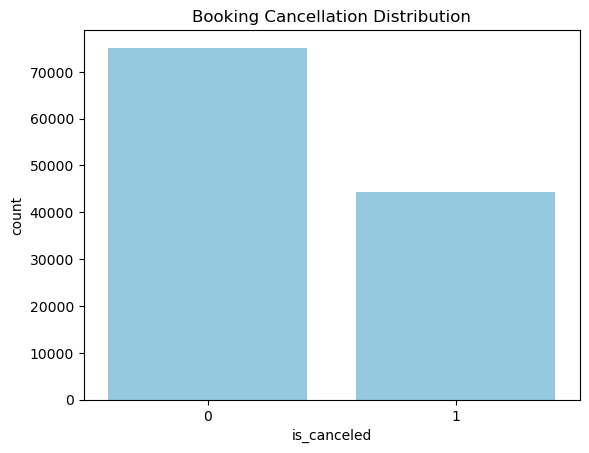

In [26]:
sns.countplot(x="is_canceled",data=df,color="skyblue")
plt.title("Booking Cancellation Distribution")
plt.show()

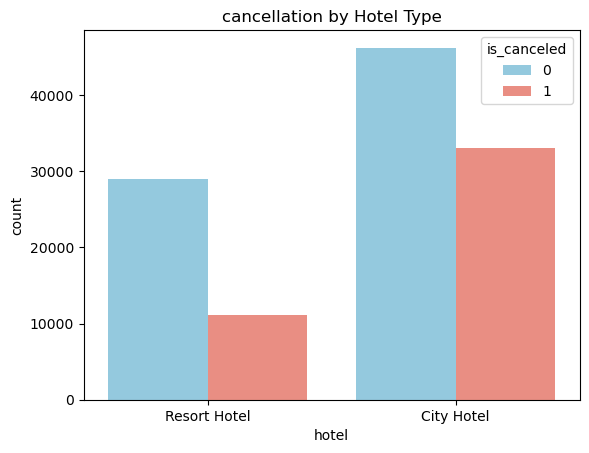

In [27]:
#Hotel type vs cancellation
sns.countplot(x="hotel",hue="is_canceled",data=df,palette=["skyblue","salmon"])
plt.title("cancellation by Hotel Type")
plt.show()

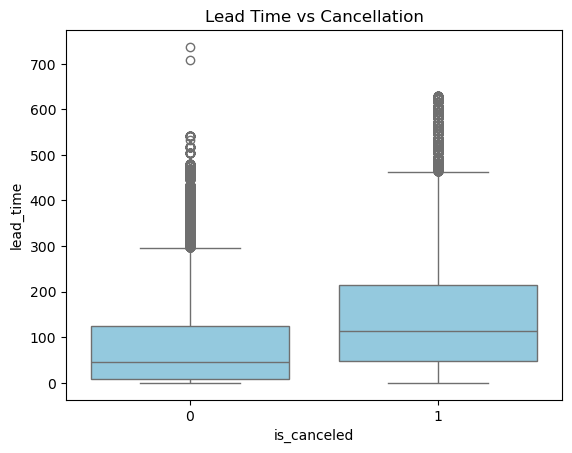

In [28]:
#Lead Time vs Cancellation
sns.boxplot(x="is_canceled",y="lead_time",data=df,color="skyblue")
plt.title("Lead Time vs Cancellation")
plt.show()

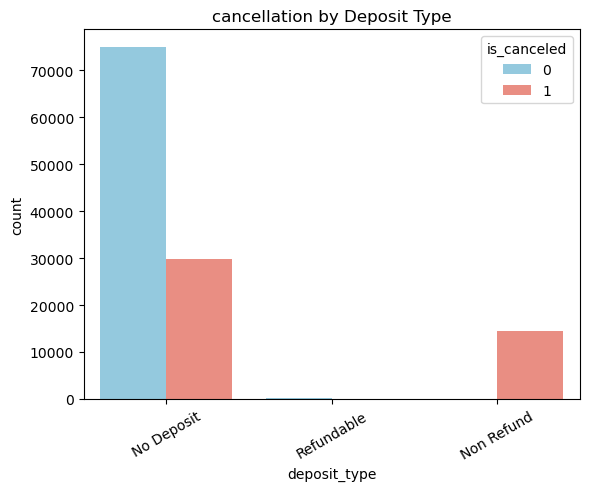

In [29]:
#Deposit Type vs Cancellation
sns.countplot(x="deposit_type",hue="is_canceled",data=df,palette=["skyblue","salmon"])
plt.title("cancellation by Deposit Type")
plt.xticks(rotation=30)
plt.show()

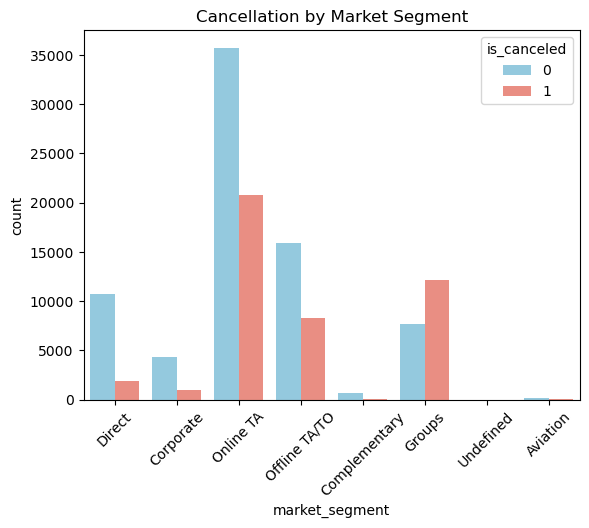

In [30]:
#Market Segment vs Cancellation
sns.countplot(x="market_segment", hue="is_canceled", data=df, palette=["skyblue", "salmon"])
plt.title("Cancellation by Market Segment")
plt.xticks(rotation=45)
plt.show()

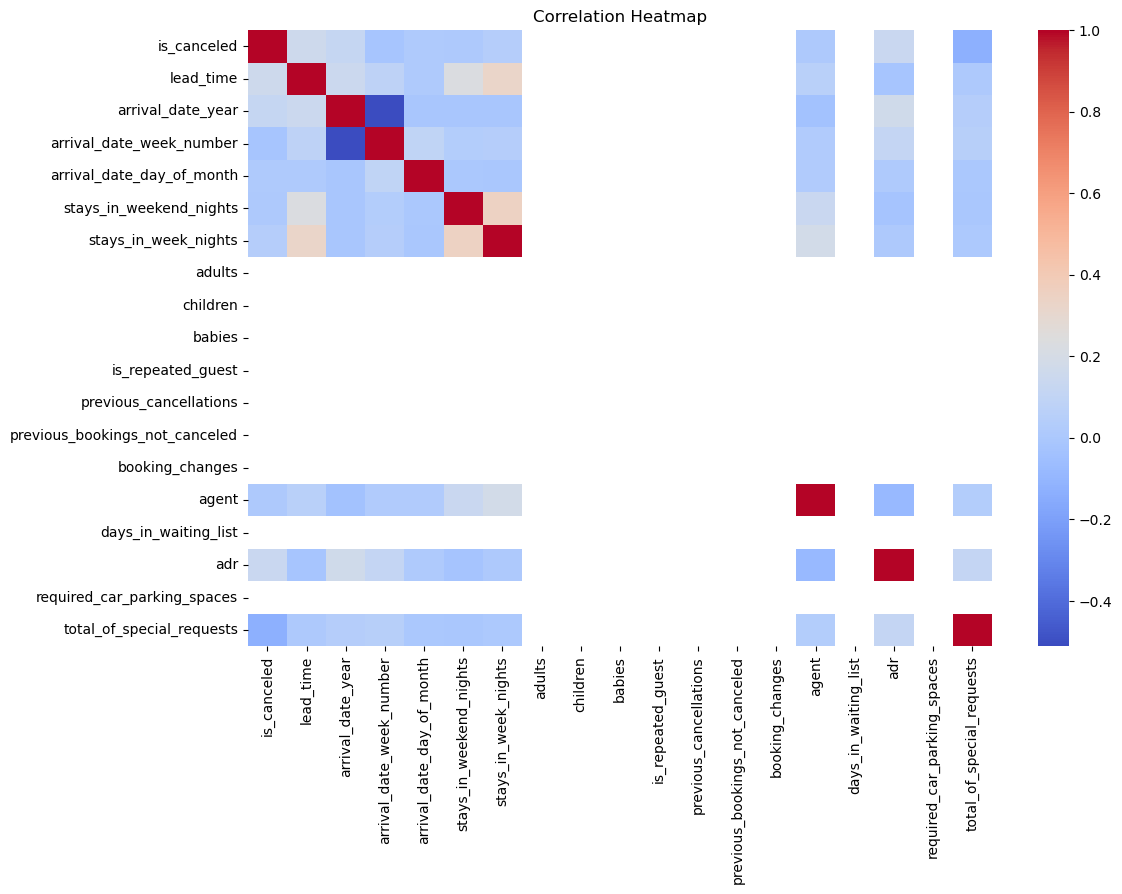

In [124]:
#correlation Analysis 
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [125]:
df.shape

(39740, 29)

In [126]:
df.select_dtypes(include="number").nunique()

is_canceled                          2
lead_time                          297
arrival_date_year                    3
arrival_date_week_number            53
arrival_date_day_of_month           31
stays_in_weekend_nights              5
stays_in_week_nights                 9
adults                               1
children                             1
babies                               1
is_repeated_guest                    1
previous_cancellations               1
previous_bookings_not_canceled       1
booking_changes                      1
agent                              235
days_in_waiting_list                 1
adr                               4838
required_car_parking_spaces          1
total_of_special_requests            3
dtype: int64

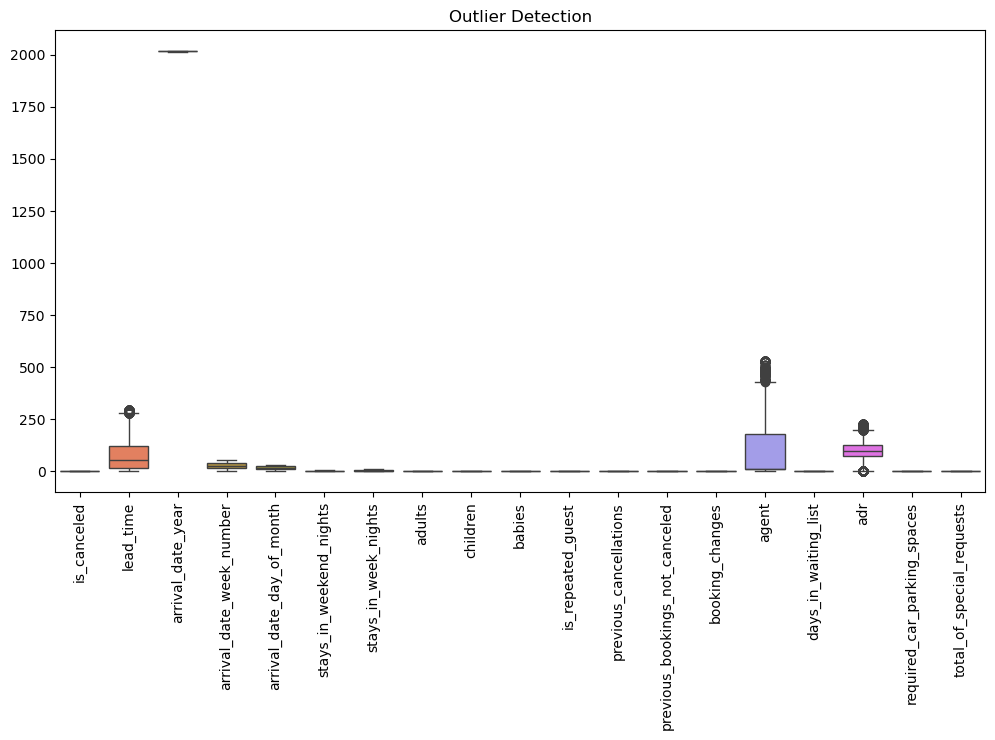

In [127]:
#outlier Dection & Treatment 
plt.figure(figsize=(12,6))
sns.boxplot(data=df.select_dtypes(include="number"))
plt.xticks(rotation=90)
plt.title("Outlier Detection")
plt.show()

In [137]:
scaler = StandardScaler()

x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [140]:
#Train-Test Split
from sklearn.model_selection import train_test_split

In [141]:
x_train,x_test,y_train,y_test = train_test_split(
    x,y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [142]:
x_train.shape,x_test.shape,y_train.shape,y_test.shape

((31792, 226), (7948, 226), (31792,), (7948,))

# Data Cleaning

In [32]:
#Checking Duplicate rows
df.duplicated().sum()

np.int64(31994)

In [33]:
df=df.drop_duplicates()

In [34]:
df.duplicated().sum()

np.int64(0)

In [38]:
#Handle missing values
df = df.copy()
df["children"] = df["children"].fillna(0)

In [39]:
df["children"].isnull().sum()

np.int64(0)

In [40]:
df["country"] = df["country"].fillna("unknow")

In [41]:
df["country"].isnull().sum()

np.int64(0)

In [42]:
df["agent"]=df["agent"].fillna(0)

In [43]:
df["agent"].isnull().sum()

np.int64(0)

In [44]:
df=df.drop("company",axis=1)

In [50]:
df.isnull().sum()[df.isnull().sum()>0]

Series([], dtype: int64)

In [51]:
df = df.drop(["reservation_status", "reservation_status_date"], axis=1)

In [52]:
df.shape

(87396, 29)

In [53]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 87396 entries, 0 to 119389
Data columns (total 29 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           87396 non-null  object 
 1   is_canceled                     87396 non-null  int64  
 2   lead_time                       87396 non-null  int64  
 3   arrival_date_year               87396 non-null  int64  
 4   arrival_date_month              87396 non-null  object 
 5   arrival_date_week_number        87396 non-null  int64  
 6   arrival_date_day_of_month       87396 non-null  int64  
 7   stays_in_weekend_nights         87396 non-null  int64  
 8   stays_in_week_nights            87396 non-null  int64  
 9   adults                          87396 non-null  int64  
 10  children                        87396 non-null  float64
 11  babies                          87396 non-null  int64  
 12  meal                            8739

In [54]:
#Separate Target and Features
x=df.drop("is_canceled",axis=1)
y=df["is_canceled"]

In [145]:
#Feature Encoding
x=df.drop("is_canceled",axis=1)
y=df["is_canceled"]

x=pd.get_dummies(
    x,
    columns=x.select_dtypes(include="object").columns,
    drop_first=True
)
x.shape

(38150, 225)

In [146]:
x.shape,y.shape

((38150, 225), (38150,))

In [147]:
x.head()

,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,...,assigned_room_type_F,assigned_room_type_G,assigned_room_type_H,assigned_room_type_I,assigned_room_type_K,deposit_type_Non Refund,deposit_type_Refundable,customer_type_Group,customer_type_Transient,customer_type_Transient-Party
4,14,2015,27,1,0,2,2,0.0,0,0,...,False,False,False,False,False,False,False,False,True,False
6,0,2015,27,1,0,2,2,0.0,0,0,...,False,False,False,False,False,False,False,False,True,False
7,9,2015,27,1,0,2,2,0.0,0,0,...,False,False,False,False,False,False,False,False,True,False
8,85,2015,27,1,0,3,2,0.0,0,0,...,False,False,False,False,False,False,False,False,True,False
9,75,2015,27,1,0,3,2,0.0,0,0,...,False,False,False,False,False,False,False,False,True,False


In [58]:
x.select_dtypes(include="object").columns

Index(['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment',
       'distribution_channel', 'reserved_room_type', 'assigned_room_type',
       'deposit_type', 'customer_type'],
      dtype='object')

In [60]:
#Encode categorical columns
x = pd.get_dummies(x, columns=x.select_dtypes(include="object").columns, drop_first=True)

In [61]:
x.shape

(87396, 247)

In [62]:
x.head()

,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,...,assigned_room_type_H,assigned_room_type_I,assigned_room_type_K,assigned_room_type_L,assigned_room_type_P,deposit_type_Non Refund,deposit_type_Refundable,customer_type_Group,customer_type_Transient,customer_type_Transient-Party
0,342,2015,27,1,0,0,2,0.0,0,0,...,False,False,False,False,False,False,False,False,True,False
1,737,2015,27,1,0,0,2,0.0,0,0,...,False,False,False,False,False,False,False,False,True,False
2,7,2015,27,1,0,1,1,0.0,0,0,...,False,False,False,False,False,False,False,False,True,False
3,13,2015,27,1,0,1,1,0.0,0,0,...,False,False,False,False,False,False,False,False,True,False
4,14,2015,27,1,0,2,2,0.0,0,0,...,False,False,False,False,False,False,False,False,True,False


In [148]:
#Feature Scaling
from sklearn.preprocessing import StandardScaler

In [149]:
Q1 = df.select_dtypes(include="number").quantile(0.25)
Q3 = df.select_dtypes(include="number").quantile(0.75)
IQR = Q3 - Q1

df = df[~((df.select_dtypes(include="number") < (Q1 - 1.5 * IQR)) |
          (df.select_dtypes(include="number") > (Q3 + 1.5 * IQR))).any(axis=1)]

df.shape

(37772, 29)

In [150]:
#Train/Test Split
from sklearn.model_selection import train_test_split

In [151]:
x_train,x_test,y_train,y_test = train_test_split(
    x,y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [152]:
x_train.shape,x_test.shape,y_train.shape,y_test.shape

((30520, 225), (7630, 225), (30520,), (7630,))

In [153]:
from sklearn.linear_model import LogisticRegression

In [154]:
#Creating the model
model = LogisticRegression(max_iter=1000)

In [155]:
model.fit(x_train,y_train)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [156]:
#Making predictions
y_pred = model.predict(x_test)

In [157]:
#Checking accuracy
from sklearn.metrics import accuracy_score

In [158]:
accuracy = accuracy_score(y_test,y_pred)
accuracy

0.7363040629095675

In [159]:
#Detailed Evaluation
from sklearn.metrics import classification_report

In [160]:
classification_report(y_test,y_pred)
classification_report

<function sklearn.metrics._classification.classification_report(y_true, y_pred, *, labels=None, target_names=None, sample_weight=None, digits=2, output_dict=False, zero_division='warn')>

In [161]:
#Evaluate Logistic Regression
from sklearn.metrics import classification_report

In [162]:
classification_report(y_test,y_pred)
classification_report

<function sklearn.metrics._classification.classification_report(y_true, y_pred, *, labels=None, target_names=None, sample_weight=None, digits=2, output_dict=False, zero_division='warn')>

In [163]:
#Confusion Matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

In [164]:
cm = confusion_matrix(y_test,y_pred)

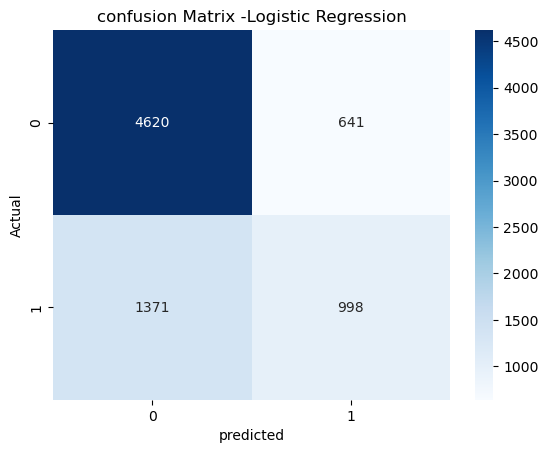

In [165]:
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues")
plt.title("confusion Matrix -Logistic Regression")
plt.xlabel("predicted")
plt.ylabel("Actual")
plt.show()

In [166]:
#ROC-AUC
from sklearn.metrics import roc_auc_score

In [167]:
y_prob = model.predict_proba(x_test)[:,1]
roc_auc_score(y_test,y_prob)
roc_auc_score

<function sklearn.metrics._ranking.roc_auc_score(y_true, y_score, *, average='macro', sample_weight=None, max_fpr=None, multi_class='raise', labels=None)>

In [168]:
#Training another model
from sklearn.tree import DecisionTreeClassifier

In [169]:
dt_model =DecisionTreeClassifier(
    random_state=42,
    max_depth=10
)
dt_model.fit(x_train,y_train)
dt_pred = dt_model.predict(x_test)

In [170]:
accuracy_score(y_test,dt_pred)
accuracy_score

<function sklearn.metrics._classification.accuracy_score(y_true, y_pred, *, normalize=True, sample_weight=None)>

In [171]:
classification_report(y_test,dt_pred)
classification_report

<function sklearn.metrics._classification.classification_report(y_true, y_pred, *, labels=None, target_names=None, sample_weight=None, digits=2, output_dict=False, zero_division='warn')>

In [172]:
from sklearn.ensemble import RandomForestClassifier

In [173]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(x_train, y_train)
rf_pred = rf_model.predict(x_test)

In [174]:
accuracy_score(y_test, rf_pred)
accuracy_score

<function sklearn.metrics._classification.accuracy_score(y_true, y_pred, *, normalize=True, sample_weight=None)>

In [175]:
classification_report(y_test,rf_pred)
classification_report

<function sklearn.metrics._classification.classification_report(y_true, y_pred, *, labels=None, target_names=None, sample_weight=None, digits=2, output_dict=False, zero_division='warn')>

In [176]:
#Comparing the models
results = pd.DataFrame({
    "Model":[
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy":[
        accuracy_score(y_test,y_pred),
        accuracy_score(y_test,dt_pred),
        accuracy_score(y_test,rf_pred)
    ],
})
results

,Model,Accuracy
0,Logistic Regression,0.736304
1,Decision Tree,0.799345
2,Random Forest,0.807077


In [177]:
final_model = rf_model
final_pred = final_model.predict(x_test)

In [178]:
accuracy_score(y_test,final_pred)

0.8070773263433814

#Final Model 
## Random Forest Was selected as the final model based on the model comparison.It achieved an accuracy of approximately 84.77% on the test dataset.

## Conclusion

The Hotel Booking Cancellation Prediction System was developed to predict wheather a hotel booking will be canceled or not.
The dataset was Cleaned & Prepared by handling missing values,Removing Duplicates,Encoding Categorical variables & Splitting The data Into Training sets.

Three Machine Learing Models were Evaluted:
- Logistic regression
- Decison Tree
- Random Forest
Random Forest achieved the highest test accuaracy of approximately "84.77%" among the models tested.
This System can help Hotels Predict booking cancellations & support better booking & room management decisons.
